# Naive Bayes Classifier Exercise 
We will work with a loan data set. <br> 
we want to predict whether a borrower will pay back the loan or not. <br>
target column is 'not.fully.paid' 

## 1. import required libraries  

In [16]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

## 2. Load data set (loan_data.csv)

In [17]:
loans = pd.read_csv('loan_data.csv')

In [18]:
loans.columns

Index(['credit.policy', 'purpose', 'int.rate', 'installment', 'log.annual.inc',
       'dti', 'fico', 'days.with.cr.line', 'revol.bal', 'revol.util',
       'inq.last.6mths', 'delinq.2yrs', 'pub.rec', 'not.fully.paid'],
      dtype='object')

## 3. Covert 'purpose' categorical column to numerical value 

In [19]:
loan_data = pd.get_dummies(loans, columns=['purpose'], drop_first=True)

## 4. Get your X and y and split the data set

In [20]:
from sklearn.model_selection import train_test_split

X = loan_data.drop('not.fully.paid', axis=1)
y = loan_data['not.fully.paid']

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

## 5. Get GaussianNB classifer 

In [22]:
from sklearn.naive_bayes import GaussianNB

nb_classifier = GaussianNB()

## 6. Train and evaluate the model  

In [23]:
from sklearn.metrics import classification_report, confusion_matrix

nb_classifier.fit(X_train, y_train)

predictions = nb_classifier.predict(X_test)

print("Confusion Matrix:\n")
print(confusion_matrix(y_test, predictions))
print("\nClassification Report:\n")
print(classification_report(y_test, predictions))


Confusion Matrix:

[[2550  100]
 [ 468   43]]

Classification Report:

              precision    recall  f1-score   support

           0       0.84      0.96      0.90      2650
           1       0.30      0.08      0.13       511

    accuracy                           0.82      3161
   macro avg       0.57      0.52      0.52      3161
weighted avg       0.76      0.82      0.78      3161



## Making a balanced data set 
Ref: https://www.datacamp.com/workspace/templates/template-python-resample-a-dataset

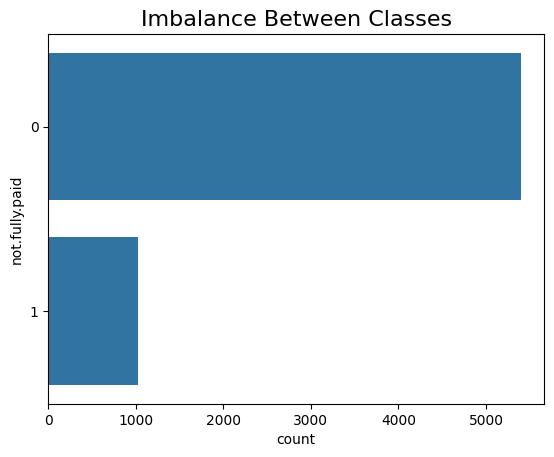

In [24]:
# Plot the counts of the training samples 
sns.countplot(y=y_train) 
plt.title("Imbalance Between Classes", size=16)
plt.show()

## 7. Get RandomUnderSampler for balancing the training data set

In [25]:
# # Import RandomOverSampler
# from imblearn.over_sampling import RandomOverSampler

# # Resample the data
# ros = RandomOverSampler(random_state=42)
# X_res, y_res = ros.fit_resample(X_train, y_train)


# Import RandomUnderSampler
from imblearn.under_sampling import RandomUnderSampler

# Resample the data
rus = RandomUnderSampler(random_state=42)
X_res, y_res = rus.fit_resample(X_train, y_train)

# # Resample the data
# from imblearn.over_sampling import SMOTE

# sm = SMOTE(random_state=42)
# X_res, y_res = sm.fit_resample(X_train, y_train)

## 8. Show that you got a balaced training samples  

<Axes: xlabel='not.fully.paid', ylabel='count'>

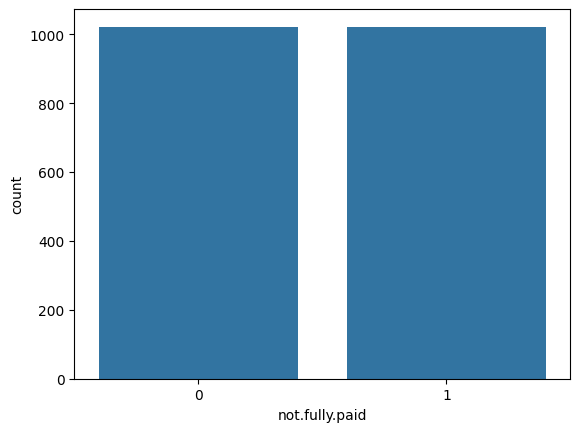

In [28]:
# Plot the counts of the training samples 
sns.countplot(x=y_res)

## 9. Retrain your model and show the updated result 

In [30]:
#Evaluate your model  
# Retrain the Gaussian Naive Bayes classifier on the balanced training set
nb_classifier.fit(X_res, y_res)

predictions_resampled = nb_classifier.predict(X_test)

## 10. Display Confusion matrix 

In [31]:
print("Confusion Matrix:\n")
print(confusion_matrix(y_test, predictions_resampled))
print("\nClassification Report:\n")
print(classification_report(y_test, predictions_resampled))

Confusion Matrix:

[[2229  421]
 [ 356  155]]

Classification Report:

              precision    recall  f1-score   support

           0       0.86      0.84      0.85      2650
           1       0.27      0.30      0.29       511

    accuracy                           0.75      3161
   macro avg       0.57      0.57      0.57      3161
weighted avg       0.77      0.75      0.76      3161



## END ## 

How to balance an imbalanced dataset: https://www.datacamp.com/workspace/templates/template-python-resample-a-dataset